# Predict Students' Dropout and Academic Success — Classification Assignment


## 1. Dataset

Source: UCI Machine Learning Repository, Dataset ID 697 — *Predict Students' Dropout and Academic Success*.

The dataset contains **4,424 student records and 36 predictor variables**. The target has three classes: **Dropout, Enrolled, and Graduate**.

In [2]:
# Install ucimlrepo package:
%pip install -q ucimlrepo

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
)

RANDOM_STATE = 42
TEST_SIZE = 0.20

PROJECT_DIR = Path.cwd()
MODEL_DIR = PROJECT_DIR / "model"
MODEL_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

In [3]:
# Load the dataset
dataset = fetch_ucirepo(id=697)

X_raw = dataset.data.features.copy()
y_raw = dataset.data.targets.copy()

# Clean the column names and target
X_raw.columns = X_raw.columns.astype(str).str.replace("\t", "", regex=False).str.strip()
y = y_raw.iloc[:, 0].astype(str).str.strip()

# Convert target labels to numbers
target_map = {
    "Dropout": 0,
    "Enrolled": 1,
    "Graduate": 2
}
if set(y.unique()).issubset(set(target_map)):
    y_encoded = y.map(target_map)
else:
    # Handles numeric target releases without changing the class meaning.
    y_encoded = y.astype(int)

print("Feature shape:", X_raw.shape)
print("Target shape:", y.shape)
print("\nTarget classes:")
print(y.value_counts())
X_raw.head()

Feature shape: (4424, 36)
Target shape: (4424,)

Target classes:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79


## 2. Data Quality and EDA

The first EDA stage checks dimensions, data types, duplicates, missing values, descriptive statistics, and target imbalance. The class imbalance is important because accuracy alone can hide weak performance on minority classes.


In [4]:
# Basic structure
print("Dataset shape:", X_raw.shape)
display(X_raw.info())

print("\nMissing values:")
display(X_raw.isna().sum().sort_values(ascending=False).head(15))

print("\nDuplicate rows:", X_raw.duplicated().sum())

print("\nDescriptive statistics:")
display(X_raw.describe().T)

print("\nTarget distribution:")
display(y.value_counts().rename_axis("Target").reset_index(name="Count"))

Dataset shape: (4424, 36)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 36 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital Status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualif

None


Missing values:


,0
Marital Status,0
Application mode,0
Application order,0
Course,0
Daytime/evening attendance,0
Previous qualification,0
Previous qualification (grade),0
Nacionality,0
Mother's qualification,0
Father's qualification,0



Duplicate rows: 0

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Marital Status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime/evening attendance,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous qualification (grade),4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mother's qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Father's qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000



Target distribution:


,Target,Count
0,Graduate,2209
1,Dropout,1421
2,Enrolled,794


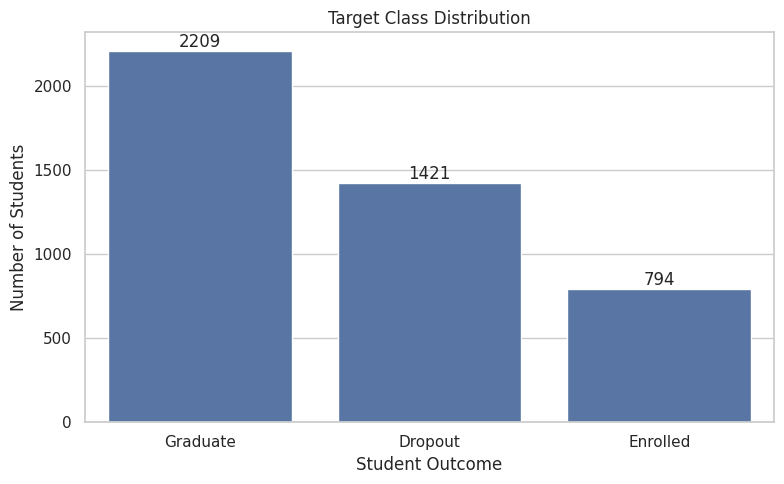

,Percentage
Target,
Graduate,49.93
Dropout,32.12
Enrolled,17.95


In [5]:
# Target class distribution
plt.figure(figsize=(8, 5))
ax = sns.countplot(x=y, order=y.value_counts().index)
plt.title("Target Class Distribution")
plt.xlabel("Student Outcome")
plt.ylabel("Number of Students")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

# Class percentages
class_pct = (y.value_counts(normalize=True) * 100).round(2)
display(class_pct.rename("Percentage").to_frame())

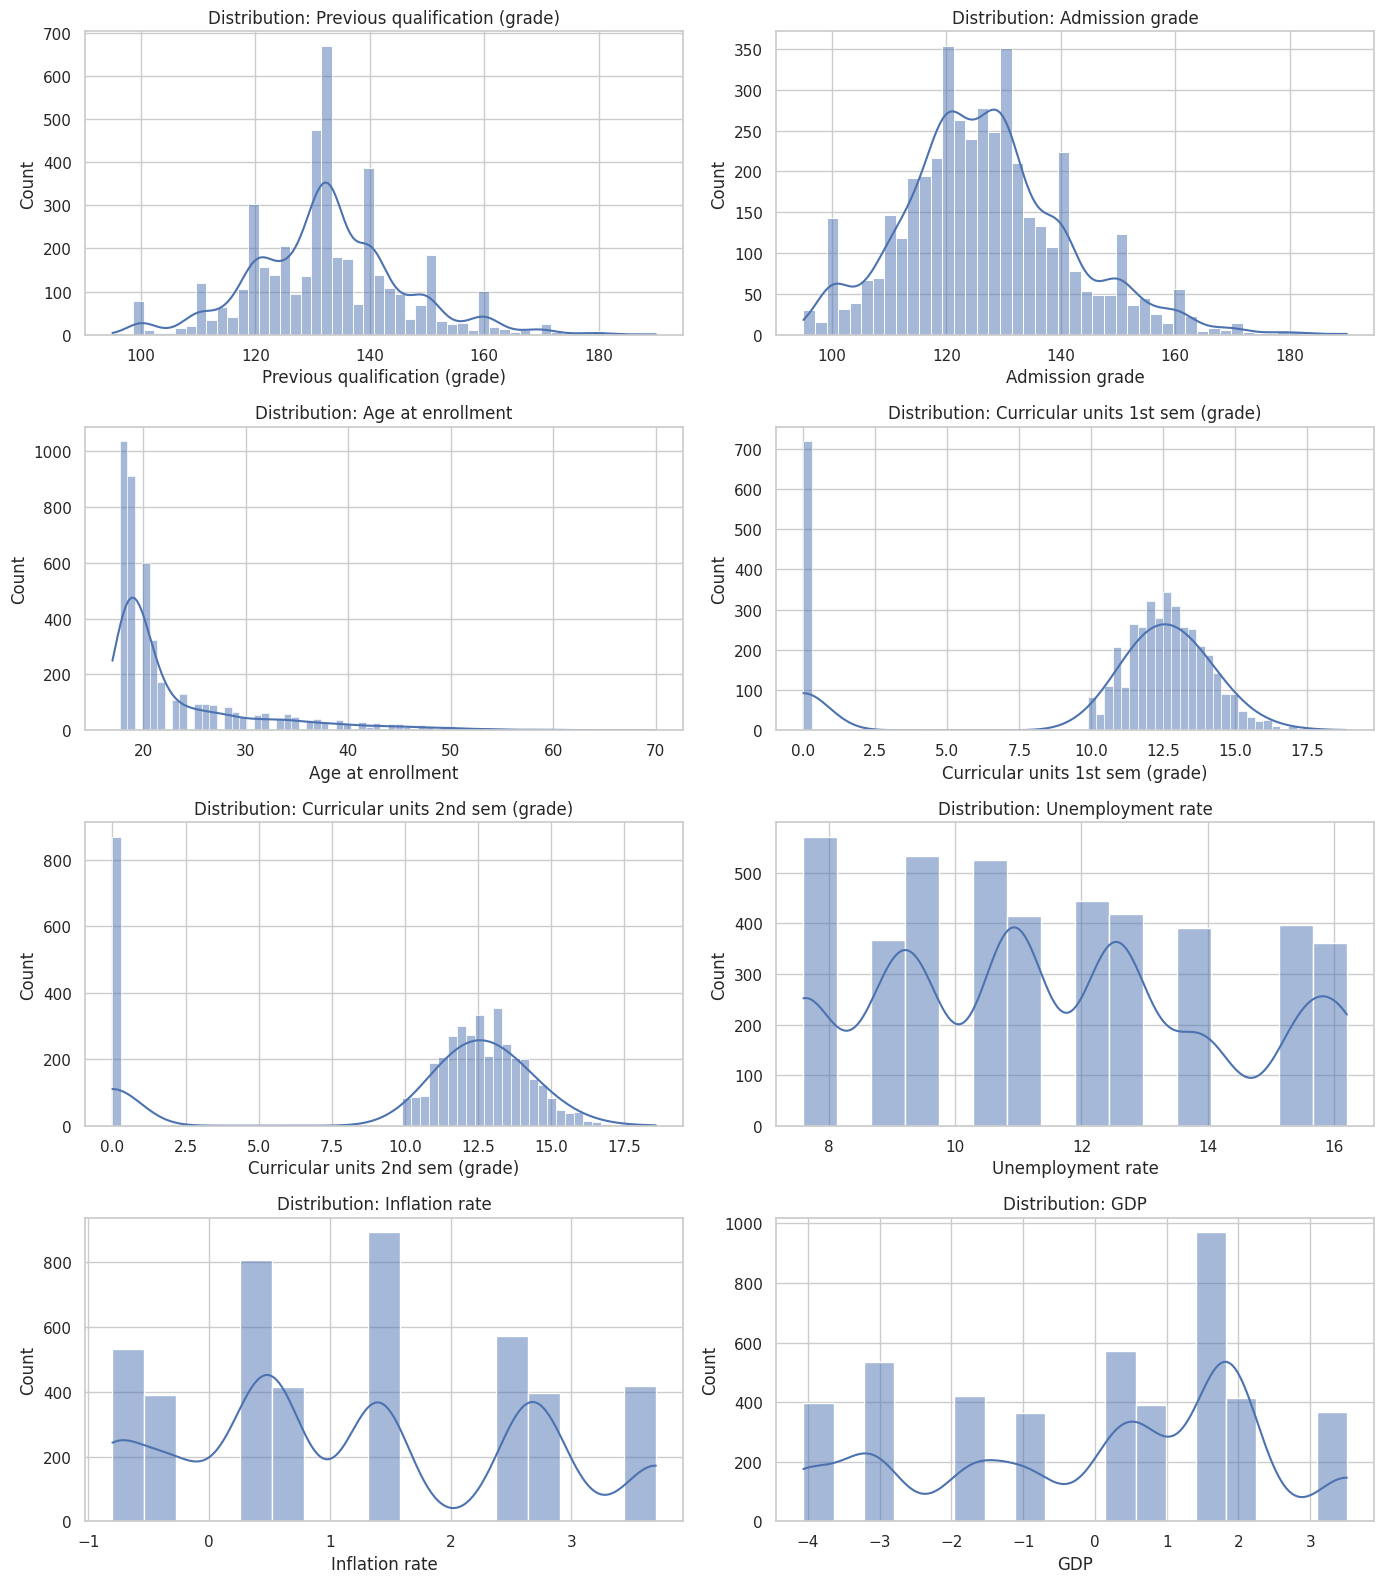

In [6]:
# Histograms for important columns
continuous_candidates = [
    "Previous qualification (grade)",
    "Admission grade",
    "Age at enrollment",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)",
    "Unemployment rate",
    "Inflation rate",
    "GDP"
]
continuous_candidates = [c for c in continuous_candidates if c in X_raw.columns]

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.ravel()

for ax, col in zip(axes, continuous_candidates):
    sns.histplot(X_raw[col], kde=True, ax=ax)
    ax.set_title(f"Distribution: {col}")
    ax.set_xlabel(col)

for ax in axes[len(continuous_candidates):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

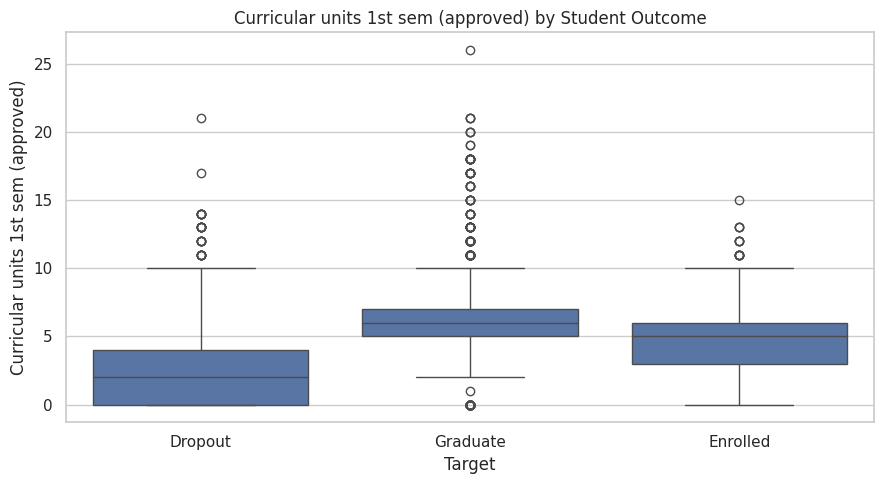

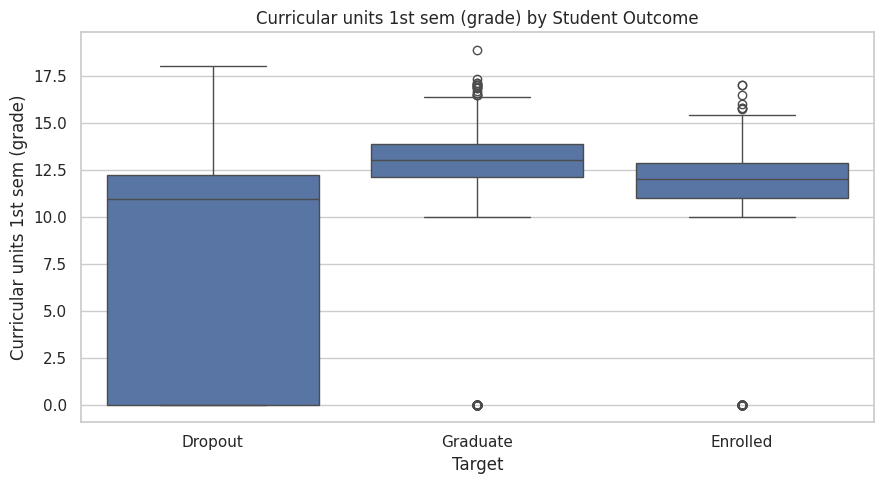

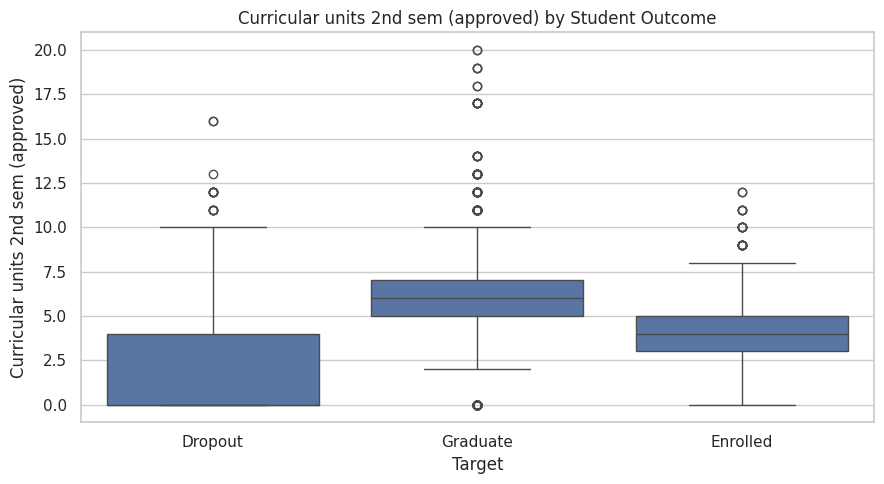

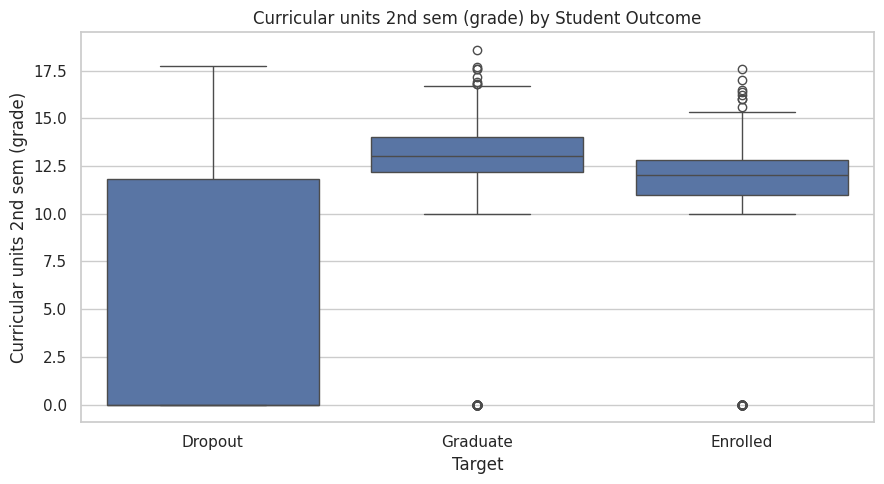

In [7]:
# Academic columns by outcome
academic_cols = [
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)"
]
academic_cols = [c for c in academic_cols if c in X_raw.columns]

eda_df = X_raw.copy()
eda_df["Target"] = y.values

for col in academic_cols:
    plt.figure(figsize=(9, 5))
    sns.boxplot(data=eda_df, x="Target", y=col)
    plt.title(f"{col} by Student Outcome")
    plt.tight_layout()
    plt.show()

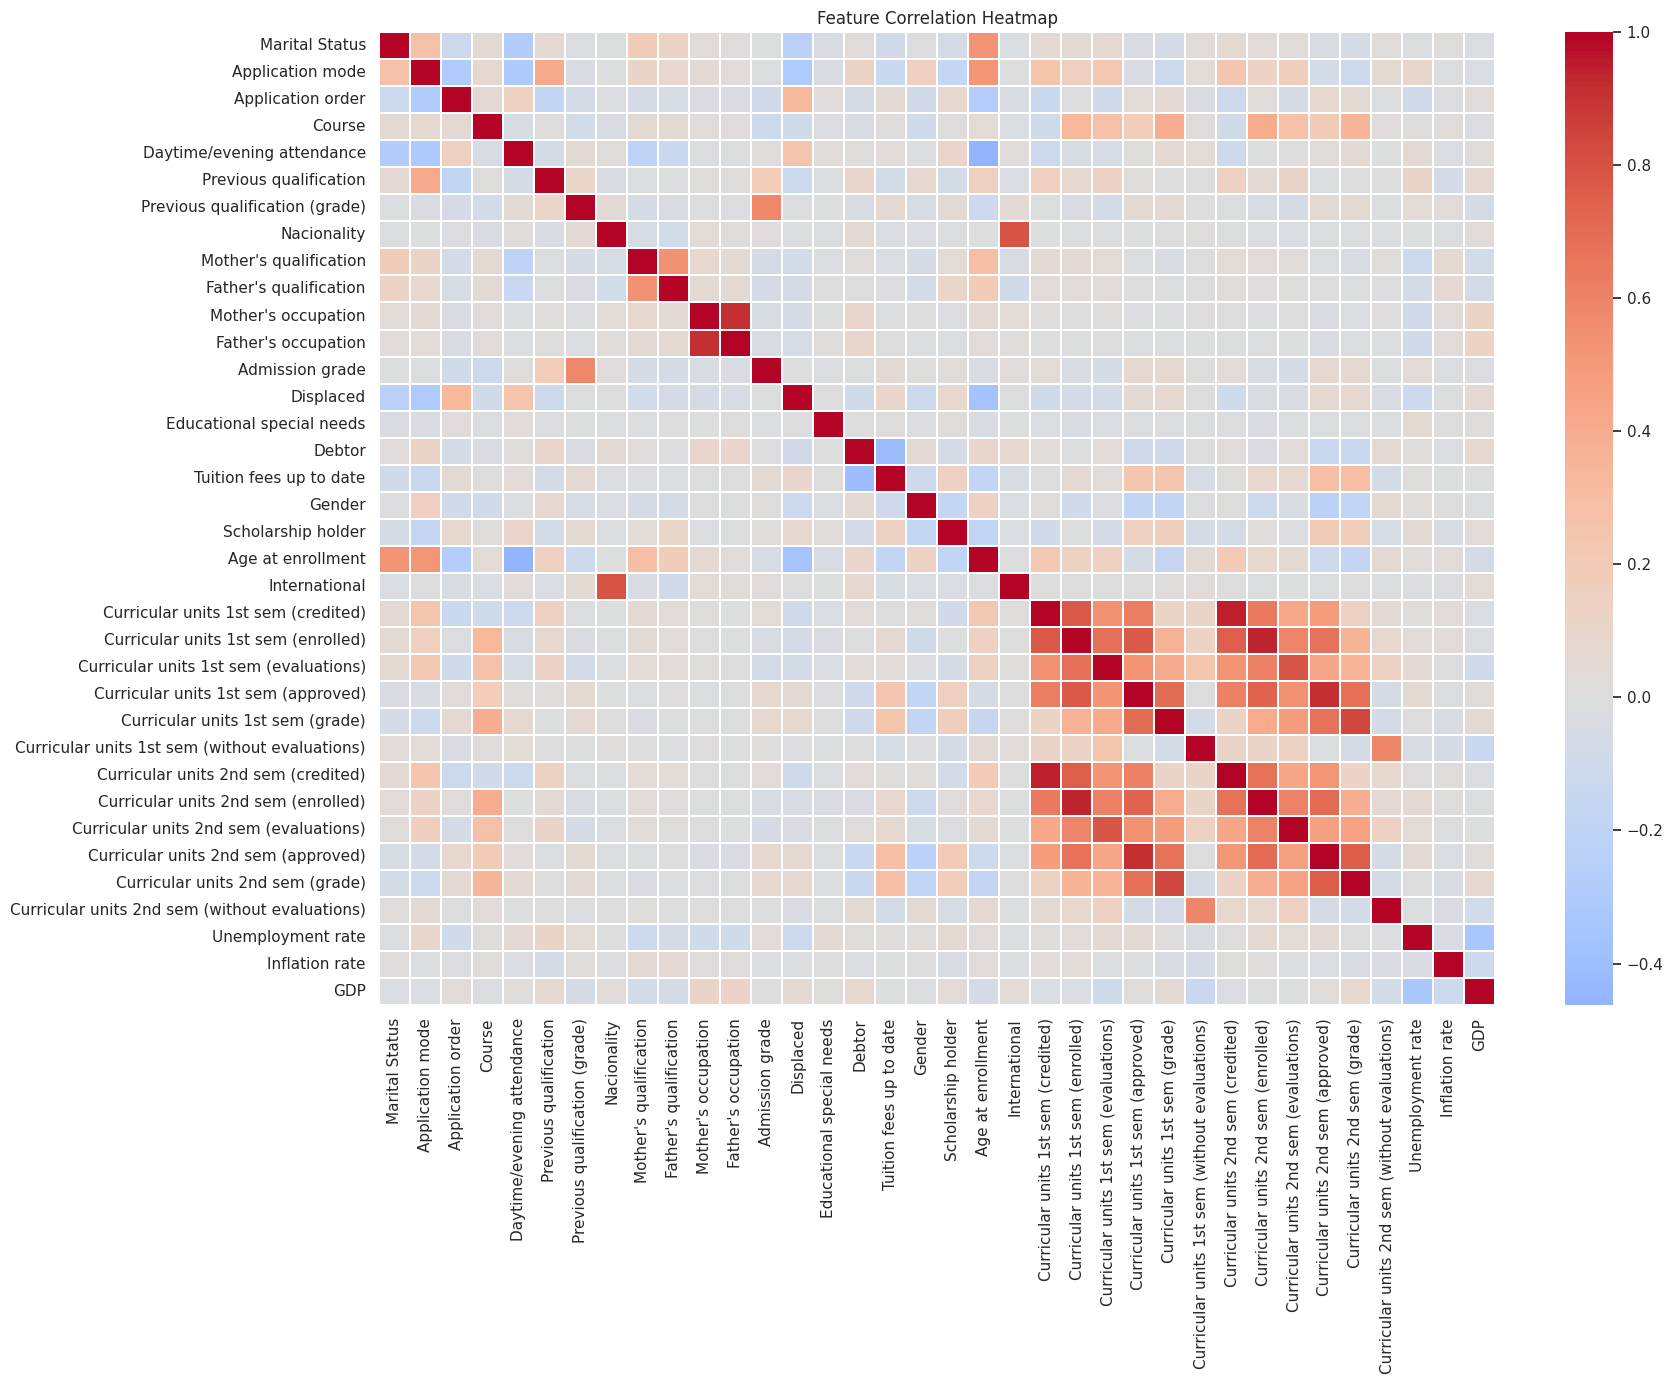

In [8]:
# Correlation heatmap
corr = X_raw.corr(numeric_only=True)

plt.figure(figsize=(18, 14))
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.1)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

## 3. Feature Engineering

The raw dataset uses many coded variables plus semester-level counts and grades. The following engineered features summarize academic progression:

- First-semester approval and evaluation rates
- Second-semester approval and evaluation rates
- Total approved units across both semesters
- Total enrolled units across both semesters
- Average semester grade
- Grade change between semesters
- Overall academic approval rate
- Financial/administrative risk indicator


In [9]:
def add_features(df):
    df = df.copy()

    # Helper function for ratios
    def ratio(num_col, den_col):
        return df[num_col] / (df[den_col].abs() + 1)

    required = set(df.columns)

    if {"Curricular units 1st sem (approved)", "Curricular units 1st sem (enrolled)"}.issubset(required):
        df["FE_1st_approval_rate"] = ratio(
            "Curricular units 1st sem (approved)",
            "Curricular units 1st sem (enrolled)"
        )

    if {"Curricular units 2nd sem (approved)", "Curricular units 2nd sem (enrolled)"}.issubset(required):
        df["FE_2nd_approval_rate"] = ratio(
            "Curricular units 2nd sem (approved)",
            "Curricular units 2nd sem (enrolled)"
        )

    if {"Curricular units 1st sem (evaluations)", "Curricular units 1st sem (enrolled)"}.issubset(required):
        df["FE_1st_evaluation_rate"] = ratio(
            "Curricular units 1st sem (evaluations)",
            "Curricular units 1st sem (enrolled)"
        )

    if {"Curricular units 2nd sem (evaluations)", "Curricular units 2nd sem (enrolled)"}.issubset(required):
        df["FE_2nd_evaluation_rate"] = ratio(
            "Curricular units 2nd sem (evaluations)",
            "Curricular units 2nd sem (enrolled)"
        )

    if {"Curricular units 1st sem (approved)", "Curricular units 2nd sem (approved)"}.issubset(required):
        df["FE_total_approved_units"] = (
            df["Curricular units 1st sem (approved)"] +
            df["Curricular units 2nd sem (approved)"]
        )

    if {"Curricular units 1st sem (enrolled)", "Curricular units 2nd sem (enrolled)"}.issubset(required):
        df["FE_total_enrolled_units"] = (
            df["Curricular units 1st sem (enrolled)"] +
            df["Curricular units 2nd sem (enrolled)"]
        )

    if {"Curricular units 1st sem (grade)", "Curricular units 2nd sem (grade)"}.issubset(required):
        df["FE_average_semester_grade"] = (
            df["Curricular units 1st sem (grade)"] +
            df["Curricular units 2nd sem (grade)"]
        ) / 2
        df["FE_grade_change"] = (
            df["Curricular units 2nd sem (grade)"] -
            df["Curricular units 1st sem (grade)"]
        )

    if {"Curricular units 1st sem (approved)", "Curricular units 2nd sem (approved)",
        "Curricular units 1st sem (enrolled)", "Curricular units 2nd sem (enrolled)"}.issubset(required):
        df["FE_overall_approval_rate"] = (
            df["Curricular units 1st sem (approved)"] +
            df["Curricular units 2nd sem (approved)"]
        ) / (
            df["Curricular units 1st sem (enrolled)"] +
            df["Curricular units 2nd sem (enrolled)"] + 1
        )

    # Create a simple fee/risk feature
    risk_cols = [c for c in ["Debtor", "Tuition fees up to date"] if c in df.columns]
    if risk_cols:
        risk = pd.Series(0, index=df.index, dtype=float)
        if "Debtor" in df.columns:
            risk += (df["Debtor"] == 1).astype(int)
        if "Tuition fees up to date" in df.columns:
            risk += (df["Tuition fees up to date"] == 0).astype(int)
        df["FE_financial_admin_risk"] = risk

    return df

X = add_features(X_raw)

print("Original features:", X_raw.shape[1])
print("Features after engineering:", X.shape[1])

engineered_cols = [c for c in X.columns if c.startswith("FE_")]
display(X[engineered_cols].describe().T)

Original features: 36
Features after engineering: 46


,count,mean,std,min,25%,50%,75%,max
FE_1st_approval_rate,4424.0,0.602822,0.316810,0.000000,0.428571,0.733333,0.857143,0.962963
FE_2nd_approval_rate,4424.0,0.570785,0.332331,0.000000,0.333333,0.714286,0.857143,0.950000
FE_1st_evaluation_rate,4424.0,1.107591,0.480999,0.000000,0.875000,1.000000,1.333333,3.000000
FE_2nd_evaluation_rate,4424.0,1.083465,0.492074,0.000000,0.857143,1.000000,1.333333,3.285714
FE_total_approved_units,4424.0,9.142405,5.960612,0.000000,5.000000,10.000000,12.000000,43.000000
FE_total_enrolled_units,4424.0,12.502712,4.608821,0.000000,10.000000,12.000000,14.000000,46.000000
FE_average_semester_grade,4424.0,10.435514,4.818530,0.000000,11.000000,12.250000,13.266667,18.283654
FE_grade_change,4424.0,-0.410616,2.890376,-16.142857,-0.600000,0.000000,0.452381,16.000000
FE_overall_approval_rate,4424.0,0.629510,0.336297,0.000000,0.454545,0.769231,0.909091,0.977273
FE_financial_admin_risk,4424.0,0.233047,0.538529,0.000000,0.000000,0.000000,0.000000,2.000000


In [10]:
# Find category and number columns
categorical_cols = [
    "Marital status",
    "Application mode",
    "Application order",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

categorical_cols += [c for c in X.columns if c.startswith("FE_financial_admin_risk")]
categorical_cols = [c for c in categorical_cols if c in X.columns]

numeric_cols = [c for c in X.columns if c not in categorical_cols]

print("Categorical features:", len(categorical_cols))
print("Numeric features:", len(numeric_cols))

Categorical features: 18
Numeric features: 28


## 4. Train/Test Split and Preprocessing

The split is **80% training / 20% testing**


In [11]:
# Train test split
X_train_raw, X_test_raw, y_train_text, y_test_text = train_test_split(
    X_raw,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

X_train = add_features(X_train_raw)
X_test = add_features(X_test_raw)

y_train = y_train_text.map(target_map).astype(int)
y_test = y_test_text.map(target_map).astype(int)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols)
    ],
    remainder="drop"
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training class distribution:")
print(y_train_text.value_counts())
print("\nTesting class distribution:")
print(y_test_text.value_counts())

Training rows: 3539
Testing rows: 885
Training class distribution:
Target
Graduate    1767
Dropout     1137
Enrolled     635
Name: count, dtype: int64

Testing class distribution:
Target
Graduate    442
Dropout     284
Enrolled    159
Name: count, dtype: int64


## 5. Classification Models

The same train/test split and preprocessing strategy are used for all five models.


In [12]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=15,
        weights="distance"
    ),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": SVC(
        kernel="rbf",
        C=2.0,
        gamma="scale",
        probability=True,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )
}

pipelines = {
    name: Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    for name, model in models.items()
}

print("Models prepared:", list(pipelines))

Models prepared: ['Logistic Regression', 'Decision Tree', 'KNN', 'Naive Bayes', 'Support Vector Machine']


In [13]:
def evaluate_model(name, pipeline, X_train, X_test, y_train, y_test):
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)

    metrics = {
        "ML Model Name": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(
            y_test, y_proba,
            multi_class="ovr",
            average="macro"
        ),
        "Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "MCC": matthews_corrcoef(y_test, y_pred)
    }
    return pipeline, metrics, y_pred, y_proba

results = []
fitted_models = {}
predictions = {}
probabilities = {}

for name, pipeline in pipelines.items():
    fitted, metrics, pred, proba = evaluate_model(
        name, pipeline, X_train, X_test, y_train, y_test
    )
    fitted_models[name] = fitted
    results.append(metrics)
    predictions[name] = pred
    probabilities[name] = proba

results_df = pd.DataFrame(results).set_index("ML Model Name")
results_df = results_df.sort_values("F1", ascending=False)

display(results_df.style.format("{:.4f}"))

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Support Vector Machine,0.7322,0.8819,0.7007,0.7043,0.6938,0.5816
Logistic Regression,0.7254,0.8810,0.6918,0.6969,0.6865,0.5727
KNN,0.7571,0.8552,0.7229,0.6556,0.6706,0.5985
Decision Tree,0.6859,0.8383,0.6765,0.6834,0.6608,0.5324
Naive Bayes,0.2452,0.7111,0.4688,0.3938,0.2187,0.1270


## 6A. Save the trained models and create the Streamlit test file

Save all five trained classifiers `model/` folder.


In [14]:
# Save all five fitted pipelines in .joblib files
MODEL_FILES = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib",
}

for name, fitted_model in fitted_models.items():
    joblib.dump(
        fitted_model,
        MODEL_DIR / MODEL_FILES[name]
    )

# Save the exact raw held-out test set for Streamlit.
test_export = X_test_raw.copy()
test_export["Target"] = y_test_text.values
test_export.to_csv(PROJECT_DIR / "test_data.csv", index=False)
print("Saved model files:")

for filename in MODEL_FILES.values():
    print(" -", MODEL_DIR / filename)

print("\nSaved:", PROJECT_DIR / "test_data.csv")
print("Test rows exported:", len(test_export))

Saved model files:
 - /content/model/logistic_regression.joblib
 - /content/model/decision_tree.joblib
 - /content/model/knn.joblib
 - /content/model/naive_bayes.joblib
 - /content/model/svm.joblib

Saved: /content/test_data.csv
Test rows exported: 885


## 6B. Basic validation of the held-out test data

The full EDA is performed on the dataset before modeling.

In [15]:
# Basic test-data checks only — no model fitting or tuning is performed here.
test_check = pd.read_csv(PROJECT_DIR / "test_data.csv")

print("Test data shape:", test_check.shape)
print("Missing values:", int(test_check.isna().sum().sum()))
print("Duplicate rows:", int(test_check.duplicated().sum()))
print("\nTest target distribution:")
display(test_check["Target"].value_counts().rename_axis("Target").reset_index(name="Count"))

print("\nTest data descriptive statistics:")
display(test_check.describe().T)

missing_test_columns = [
    c for c in X_raw.columns if c not in test_check.columns
]
print("\nMissing required input columns:", missing_test_columns)

Test data shape: (885, 37)
Missing values: 0
Duplicate rows: 0

Test target distribution:


,Target,Count
0,Graduate,442
1,Dropout,284
2,Enrolled,159



Test data descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Marital Status,885.0,1.195480,0.639200,1.00,1.00,1.00,1.000,6.000000
Application mode,885.0,18.701695,17.484875,1.00,1.00,17.00,39.000,53.000000
Application order,885.0,1.731073,1.340289,1.00,1.00,1.00,2.000,6.000000
Course,885.0,8879.259887,1992.266563,33.00,9085.00,9238.00,9556.000,9991.000000
Daytime/evening attendance,885.0,0.885876,0.318142,0.00,1.00,1.00,1.000,1.000000
Previous qualification,885.0,4.054237,9.270532,1.00,1.00,1.00,1.000,42.000000
Previous qualification (grade),885.0,132.327797,13.136093,100.00,124.00,133.10,140.000,180.000000
Nacionality,885.0,2.005650,7.121837,1.00,1.00,1.00,1.000,109.000000
Mother's qualification,885.0,19.964972,15.755769,1.00,2.00,19.00,37.000,43.000000
Father's qualification,885.0,22.211299,15.427890,1.00,3.00,19.00,37.000,39.000000



Missing required input columns: []


## 6. Required Comparison Table

In [16]:
comparison_table = results_df.reset_index().copy()

display(
    comparison_table.style
    .format({
        "Accuracy": "{:.4f}",
        "AUC": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "MCC": "{:.4f}"
    })
    .background_gradient(cmap="Blues", subset=[
        "Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"
    ])
)

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Support Vector Machine,0.7322,0.8819,0.7007,0.7043,0.6938,0.5816
1,Logistic Regression,0.7254,0.8810,0.6918,0.6969,0.6865,0.5727
2,KNN,0.7571,0.8552,0.7229,0.6556,0.6706,0.5985
3,Decision Tree,0.6859,0.8383,0.6765,0.6834,0.6608,0.5324
4,Naive Bayes,0.2452,0.7111,0.4688,0.3938,0.2187,0.1270


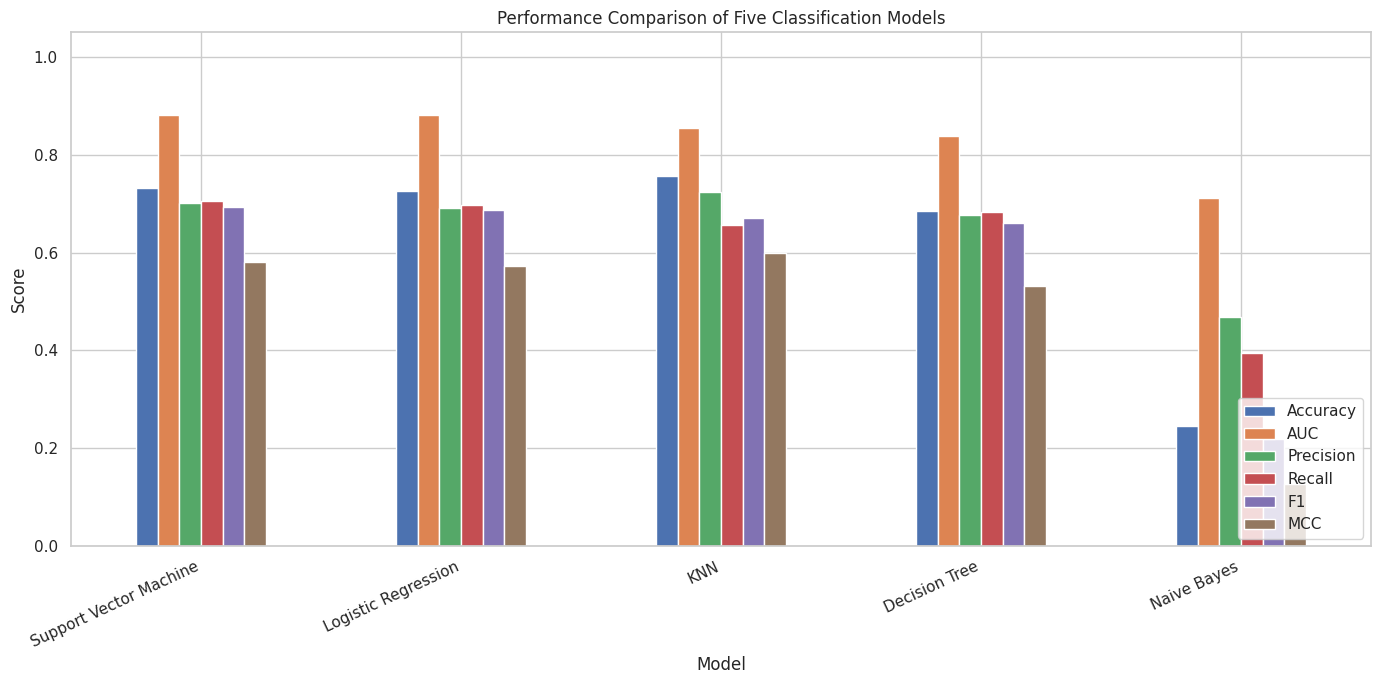

In [17]:
# Compare all metrics
plot_df = results_df[["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]]

ax = plot_df.plot(kind="bar", figsize=(14, 7))
plt.title("Performance Comparison of Five Classification Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 7. Confusion Matrices

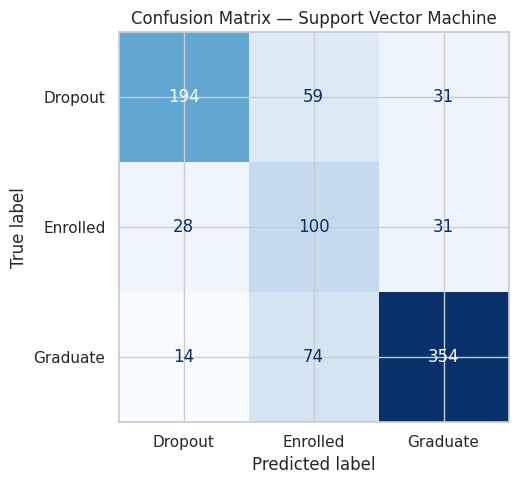

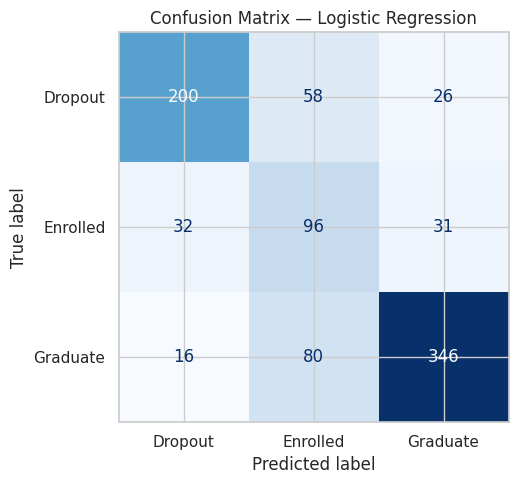

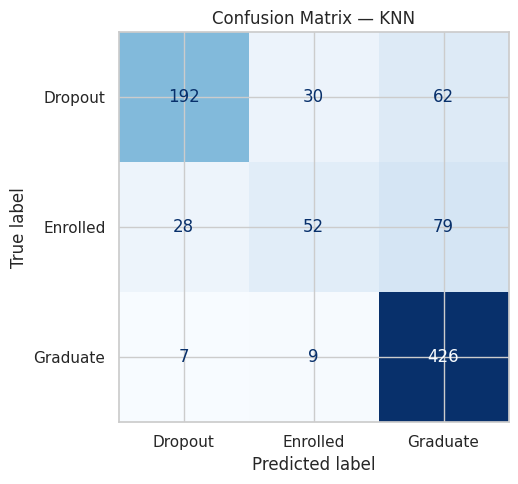

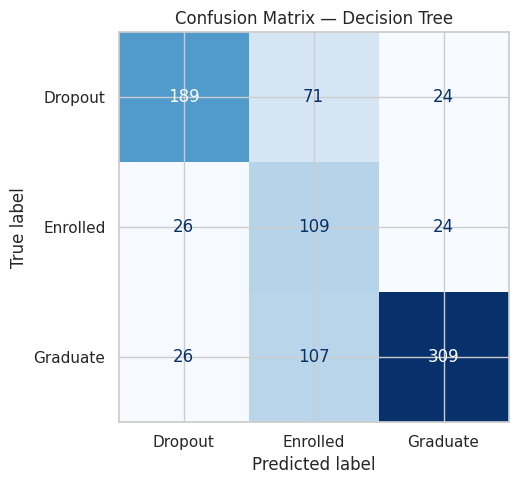

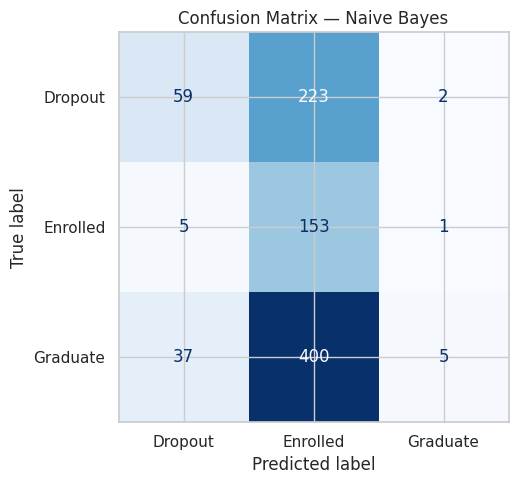

In [18]:
class_names = ["Dropout", "Enrolled", "Graduate"]

for name in results_df.index:
    cm = confusion_matrix(y_test, predictions[name], labels=[0, 1, 2])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    fig, ax = plt.subplots(figsize=(6, 5))
    disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

## 8. ROC Curves

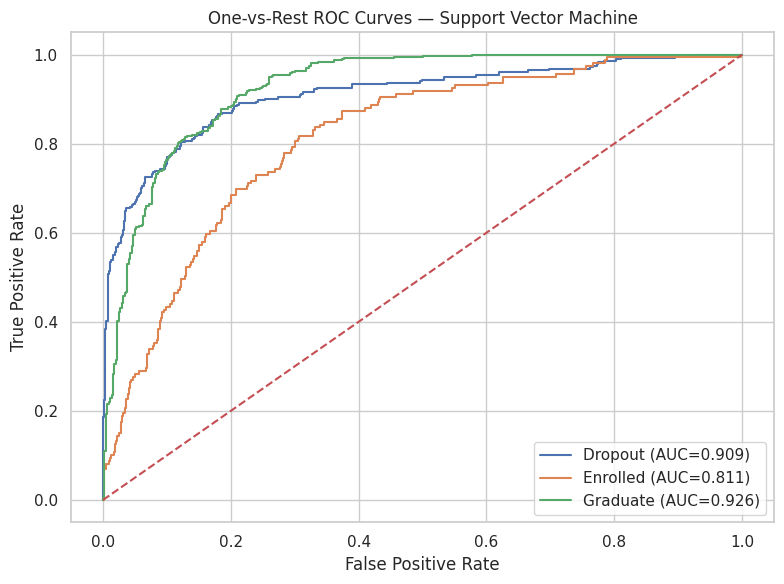

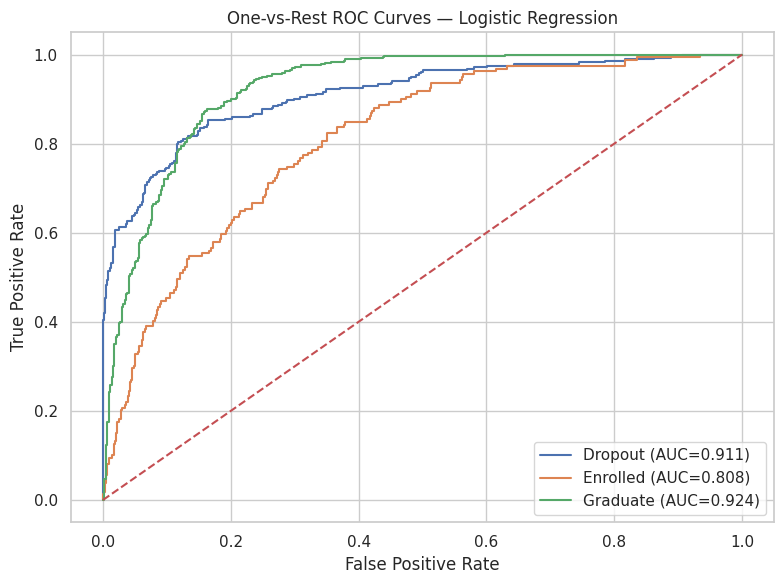

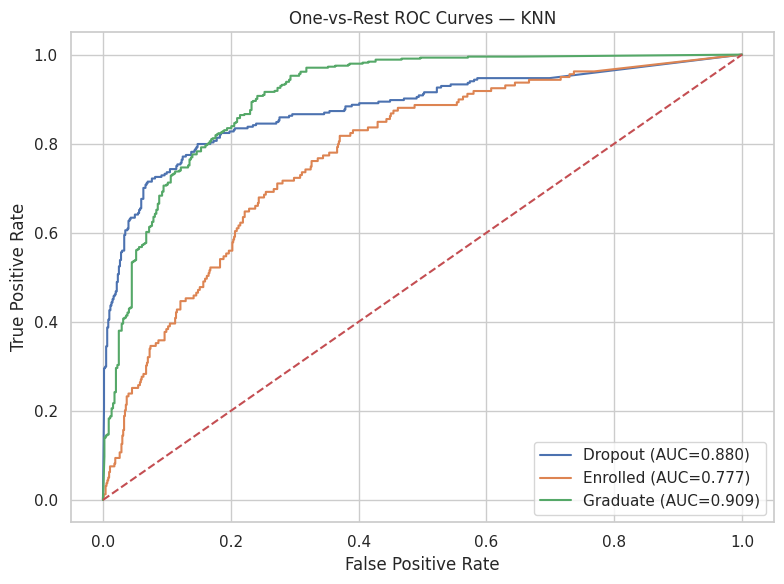

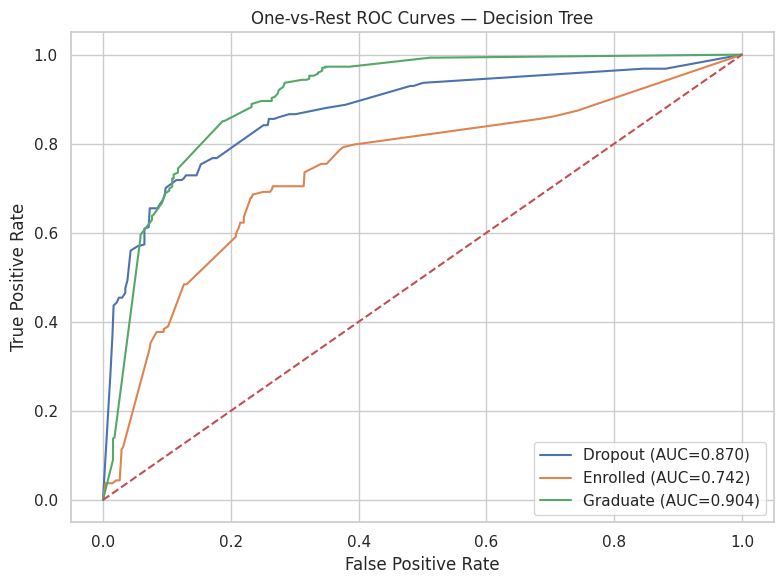

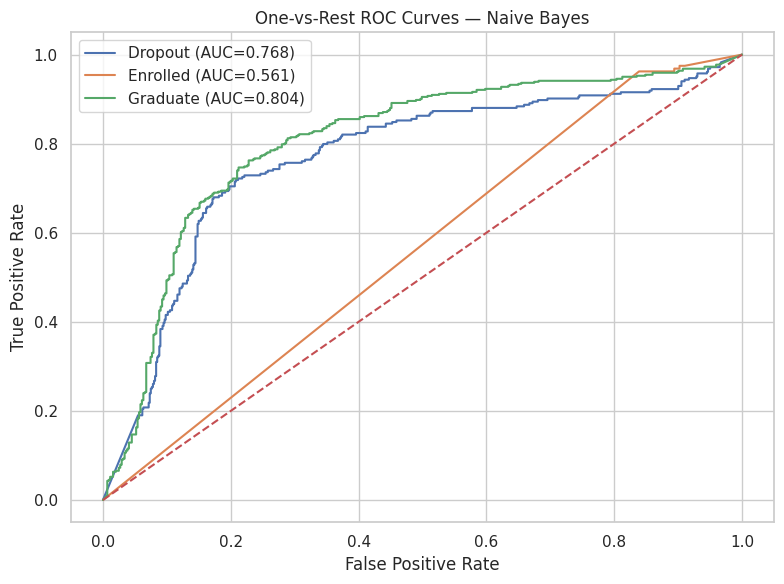

In [19]:
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

for name in results_df.index:
    proba = probabilities[name]

    plt.figure(figsize=(8, 6))
    for i, class_name in enumerate(class_names):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], proba[:, i])
        class_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"{class_name} (AUC={class_auc:.3f})")

    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"One-vs-Rest ROC Curves — {name}")
    plt.legend()
    plt.tight_layout()
    plt.show()

## 9. Detailed Classification Reports

Macro-average metrics are used for the required comparison, while the classification reports below provide class-by-class Precision, Recall, and F1.


In [20]:
for name in results_df.index:
    print("=" * 80)
    print(name)
    print("=" * 80)
    print(classification_report(
        y_test,
        predictions[name],
        target_names=class_names,
        digits=4,
        zero_division=0
    ))

Support Vector Machine
              precision    recall  f1-score   support

     Dropout     0.8220    0.6831    0.7462       284
    Enrolled     0.4292    0.6289    0.5102       159
    Graduate     0.8510    0.8009    0.8252       442

    accuracy                         0.7322       885
   macro avg     0.7007    0.7043    0.6938       885
weighted avg     0.7659    0.7322    0.7432       885

Logistic Regression
              precision    recall  f1-score   support

     Dropout     0.8065    0.7042    0.7519       284
    Enrolled     0.4103    0.6038    0.4885       159
    Graduate     0.8586    0.7828    0.8189       442

    accuracy                         0.7254       885
   macro avg     0.6918    0.6969    0.6865       885
weighted avg     0.7613    0.7254    0.7381       885

KNN
              precision    recall  f1-score   support

     Dropout     0.8458    0.6761    0.7515       284
    Enrolled     0.5714    0.3270    0.4160       159
    Graduate     0.7513    0

## 10. Model Interpretation

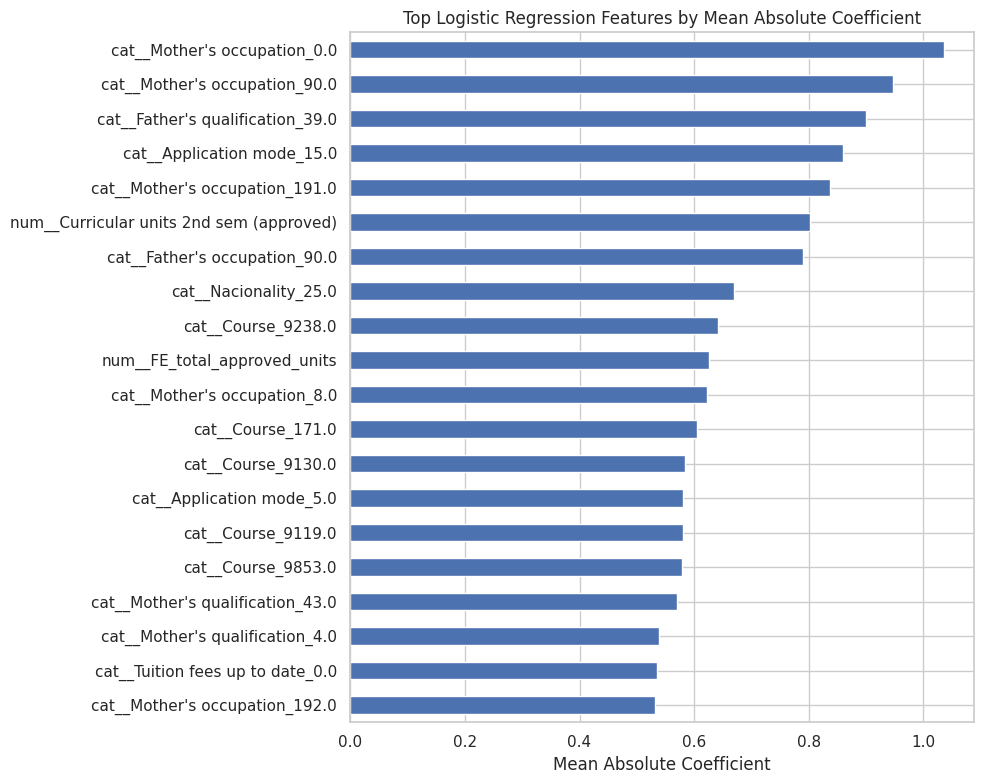

,Mean Absolute Coefficient
cat__Mother's occupation_0.0,1.036593
cat__Mother's occupation_90.0,0.946928
cat__Father's qualification_39.0,0.900234
cat__Application mode_15.0,0.859847
cat__Mother's occupation_191.0,0.836636
num__Curricular units 2nd sem (approved),0.802733
cat__Father's occupation_90.0,0.789240
cat__Nacionality_25.0,0.669207
cat__Course_9238.0,0.641734
num__FE_total_approved_units,0.625675


In [21]:
# Logistic Regression feature importance
log_pipe = fitted_models["Logistic Regression"]
feature_names = log_pipe.named_steps["preprocessor"].get_feature_names_out()
log_model = log_pipe.named_steps["model"]

coef_strength = np.mean(np.abs(log_model.coef_), axis=0)
log_importance = (
    pd.Series(coef_strength, index=feature_names)
    .sort_values(ascending=False)
    .head(20)
)

plt.figure(figsize=(10, 8))
log_importance.sort_values().plot(kind="barh")
plt.title("Top Logistic Regression Features by Mean Absolute Coefficient")
plt.xlabel("Mean Absolute Coefficient")
plt.tight_layout()
plt.show()

display(log_importance.to_frame("Mean Absolute Coefficient"))

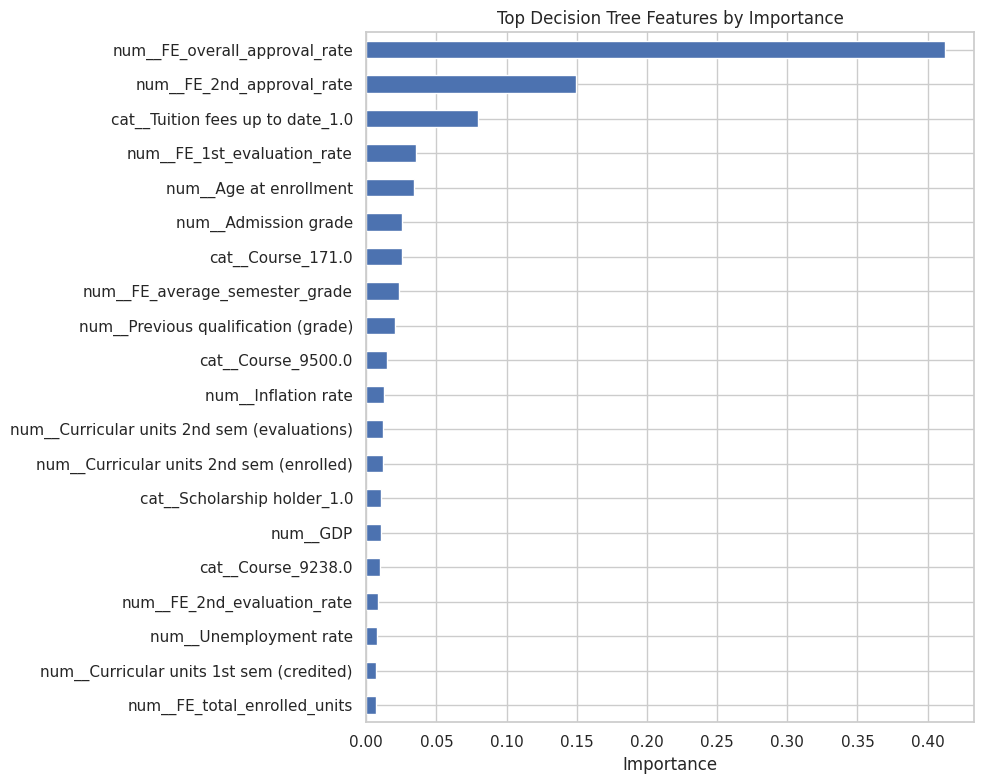

,Importance
num__FE_overall_approval_rate,0.412397
num__FE_2nd_approval_rate,0.149451
cat__Tuition fees up to date_1.0,0.079886
num__FE_1st_evaluation_rate,0.035532
num__Age at enrollment,0.034055
num__Admission grade,0.025763
cat__Course_171.0,0.025339
num__FE_average_semester_grade,0.023705
num__Previous qualification (grade),0.020799
cat__Course_9500.0,0.014658


In [22]:
# Decision Tree feature importance
tree_pipe = fitted_models["Decision Tree"]
tree_features = tree_pipe.named_steps["preprocessor"].get_feature_names_out()
tree_model = tree_pipe.named_steps["model"]

tree_importance = (
    pd.Series(tree_model.feature_importances_, index=tree_features)
    .sort_values(ascending=False)
    .head(20)
)

plt.figure(figsize=(10, 8))
tree_importance.sort_values().plot(kind="barh")
plt.title("Top Decision Tree Features by Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

display(tree_importance.to_frame("Importance"))

## 11. Automatic Winner and Observations


In [23]:
winner = results_df["F1"].idxmax()

observation_templates = {
    "Logistic Regression": "A strong linear baseline; performance reflects how well the standardized and one-hot encoded features separate the three outcomes with a linear decision boundary.",
    "Decision Tree": "Captures nonlinear interactions and threshold effects. Its depth and minimum-leaf constraints help reduce overfitting.",
    "KNN": "Uses local similarity in the transformed feature space. Standardization is important because distance-based methods are sensitive to feature scale.",
    "Naive Bayes": "A fast probabilistic baseline based on conditional independence assumptions. It can perform well when those assumptions are approximately reasonable, but correlated features can reduce effectiveness.",
    "Support Vector Machine": "Uses an RBF kernel to model nonlinear class boundaries. Scaling and class weighting help it handle heterogeneous features and class imbalance."
}

observations = pd.DataFrame({
    "ML Model Name": list(observation_templates.keys()),
    "Observation about model performance": [
        observation_templates[name] +
        f" Test-set macro F1 = {results_df.loc[name, 'F1']:.4f}, "
        f"Accuracy = {results_df.loc[name, 'Accuracy']:.4f}."
        for name in observation_templates
    ]
})

display(observations)

print(f"Overall Winner for this dataset: {winner}")
print(f"Winner's macro F1: {results_df.loc[winner, 'F1']:.4f}")

,ML Model Name,Observation about model performance
0,Logistic Regression,A strong linear baseline; performance reflects...
1,Decision Tree,Captures nonlinear interactions and threshold ...
2,KNN,Uses local similarity in the transformed featu...
3,Naive Bayes,A fast probabilistic baseline based on conditi...
4,Support Vector Machine,Uses an RBF kernel to model nonlinear class bo...


Overall Winner for this dataset: Support Vector Machine
Winner's macro F1: 0.6938
